<a href="https://colab.research.google.com/github/jaianes/tcc-mulheres-ti/blob/main/ANALISE_DADOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 1 — State of Data Brazil (área de Dados), 2021–2025

Configuração, carga dos dados, análise de cada edição, resumo comparativo e testes estatísticos (Objetivo 4).

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import unicodedata

PASTA = "/content/drive/MyDrive/TCC/dados/"

PONTOS_MEDIOS = {
    'Menos de R$ 1.000/mês': 750,
    'de R$ 1.001/mês a R$ 2.000/mês': 1500,
    'de R$ 2.001/mês a R$ 3000/mês': 2500,
    'de R$ 2.001/mês a R$ 3.000/mês': 2500,
    'de R$ 101/mês a R$ 2.000/mês': 1050,
    'de R$ 25.001/mês a R$ 3000/mês': 27500,
    'de R$ 3.001/mês a R$ 4.000/mês': 3500,
    'de R$ 4.001/mês a R$ 6.000/mês': 5000,
    'de R$ 6.001/mês a R$ 8.000/mês': 7000,
    'de R$ 8.001/mês a R$ 12.000/mês': 10000,
    'de R$ 12.001/mês a R$ 16.000/mês': 14000,
    'de R$ 16.001/mês a R$ 20.000/mês': 18000,
    'de R$ 20.001/mês a R$ 25.000/mês': 22500,
    'de R$ 25.001/mês a R$ 30.000/mês': 27500,
    'de R$ 30.001/mês a R$ 40.000/mês': 35000,
    'Acima de R$ 40.001/mês': 45000,
}

# grupos de cargo FIXOS, os mesmos em todos os anos
GRUPOS_CARGO = [
    ("Analista de BI", ["analista de bi", "bi analyst", "business intelligence", "analytics engineer"]),
    ("Analista de Dados", ["analista de dados", "data analyst"]),
    ("Cientista de Dados", ["cientista de dados", "data scientist"]),
    ("Engenheiro/Arquiteto de Dados", ["engenheiro de dados", "data engineer", "arquiteto de dados", "data architect"]),
]
ORDEM_CARGOS = [g for g, _ in GRUPOS_CARGO]
CORES = {"Feminino": "#FF2D55", "Masculino": "#0A58D6"}


def norm(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()


def limpar_nome(col):
    m = re.match(r"^\('.*?',\s*'(.*)'\)$", str(col))
    return m.group(1) if m else str(col)


def agrupar_cargo(texto):
    if pd.isna(texto):
        return pd.NA
    t = norm(texto)
    for grupo, chaves in GRUPOS_CARGO:
        if any(k in t for k in chaves):
            return grupo
    return "Outros"


def carregar_edicao(ano, col_genero, col_cargo, col_faixa, col_nivel=None):
    df = pd.read_csv(f"{PASTA}Dados_{ano}.csv", low_memory=False)
    df.columns = [limpar_nome(c) for c in df.columns]

    nomes = {col_genero: "Genero", col_cargo: "Cargo", col_faixa: "Faixa"}
    if col_nivel:
        nomes[col_nivel] = "Nivel"
    df = df.rename(columns=nomes)

    df["Ano"] = ano
    df["Cargo"] = df["Cargo"].str.strip()
    df["Cargo_grupo"] = df["Cargo"].map(agrupar_cargo)
    df["Salario_estimado"] = df["Faixa"].astype(str).str.strip().map(PONTOS_MEDIOS)

    # ---- checagens (leia o que aparece!) ----
    print(f"Edição {ano}: {df.shape[0]} linhas, {df.shape[1]} colunas")
    print("Gênero:", df["Genero"].value_counts(dropna=False).to_dict())
    print(f"Faixa salarial informada: {df['Faixa'].notna().sum()} | convertida em salário: {df['Salario_estimado'].notna().sum()}")
    nao_mapeadas = df.loc[df["Faixa"].notna() & df["Salario_estimado"].isna(), "Faixa"].value_counts()
    if len(nao_mapeadas):
        print("ATENÇÃO, faixas sem correspondência no dicionário:")
        print(nao_mapeadas)
    else:
        print("Todas as faixas informadas foram reconhecidas.")
    return df

In [ ]:
dados = {}   # guarda todos os anos ao mesmo tempo, sem um sobrescrever o outro
dados[2021] = carregar_edicao(2021, col_genero="Genero", col_cargo="Cargo Atual",
                              col_faixa="Faixa salarial", col_nivel="Nivel")

Edição 2021: 2645 linhas, 359 colunas
Gênero: {'Masculino': 2144, 'Feminino': 493, 'Outro': 8}
Faixa salarial informada: 2365 | convertida em salário: 2365
Todas as faixas informadas foram reconhecidas.


In [ ]:
def resumo(df):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])]
    med = d.groupby("Genero")["Salario_estimado"].mean()
    n_sal = d.groupby("Genero")["Salario_estimado"].count()
    return pd.Series({
        "Ano": int(df["Ano"].iloc[0]),
        "Respondentes": len(df),
        "Mulheres (%)": round(100 * (d["Genero"] == "Feminino").mean(), 1),
        "Média salarial F": round(med["Feminino"]),
        "Média salarial M": round(med["Masculino"]),
        "Diferença (%)": round((med["Masculino"] - med["Feminino"]) / med["Masculino"] * 100, 1),
        "n com salário F": n_sal["Feminino"],
        "n com salário M": n_sal["Masculino"],
    })

tabela = pd.DataFrame([resumo(dados[a]) for a in dados]).set_index("Ano")
tabela

,Respondentes,Mulheres (%),Média salarial F,Média salarial M,Diferença (%),n com salário F,n com salário M
Ano,,,,,,,
2021.0,2645.0,18.7,8067.0,9736.0,17.1,436.0,1924.0


In [ ]:
de_para = (dados[2021].groupby(["Cargo_grupo", "Cargo"], dropna=False)
           .size().rename("n").reset_index())
de_para

,Cargo_grupo,Cargo,n
0,Analista de BI,Analista de BI/BI Analyst/Analytics Engineer,338
1,Analista de Dados,Analista de Dados/Data Analyst,324
2,Cientista de Dados,Cientista de Dados/Data Scientist,357
3,Engenheiro/Arquiteto de Dados,Arquiteto de Dados,7
4,Engenheiro/Arquiteto de Dados,Arquiteto de dados,2
5,Engenheiro/Arquiteto de Dados,Engenheiro de Dados/Data Engineer,300
6,Outros,Analista Administrativo,18
7,Outros,Analista de Inteligência de Mercado/Market Int...,18
8,Outros,Analista de Marketing,14
9,Outros,Analista de Negócios/Business Analyst,96


## Gráfico 1 — Salário médio estimado por gênero

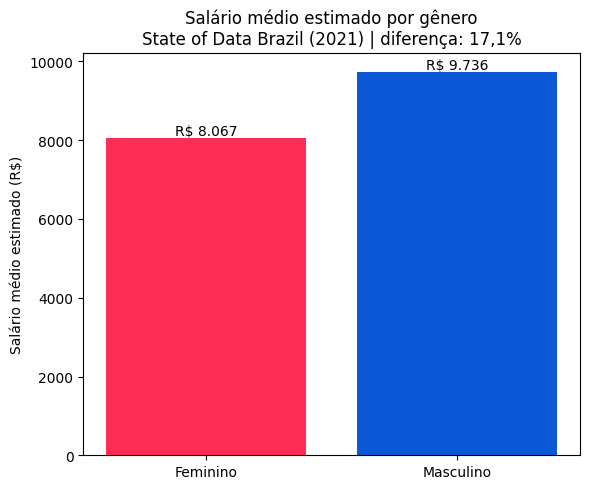

In [ ]:
def grafico_salario(df, ano):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])]
    med = d.groupby("Genero")["Salario_estimado"].mean()
    dif = (med["Masculino"] - med["Feminino"]) / med["Masculino"] * 100
    dif_txt = f"{dif:.1f}".replace(".", ",")

    fig, ax = plt.subplots(figsize=(6, 5))
    barras = ax.bar(["Feminino", "Masculino"], [med["Feminino"], med["Masculino"]],
                    color=[CORES["Feminino"], CORES["Masculino"]])
    ax.bar_label(barras, labels=[f"R$ {v:,.0f}".replace(",", ".") for v in (med["Feminino"], med["Masculino"])])
    ax.set_ylabel("Salário médio estimado (R$)")
    ax.set_title(f"Salário médio estimado por gênero\nState of Data Brazil ({ano}) | diferença: {dif_txt}%")
    fig.tight_layout()
    fig.savefig(f"grafico1_salario_{ano}.png", dpi=200, bbox_inches="tight")
    plt.show()

grafico_salario(dados[2021], 2021)

## Gráfico 2 — Cargos por gênero

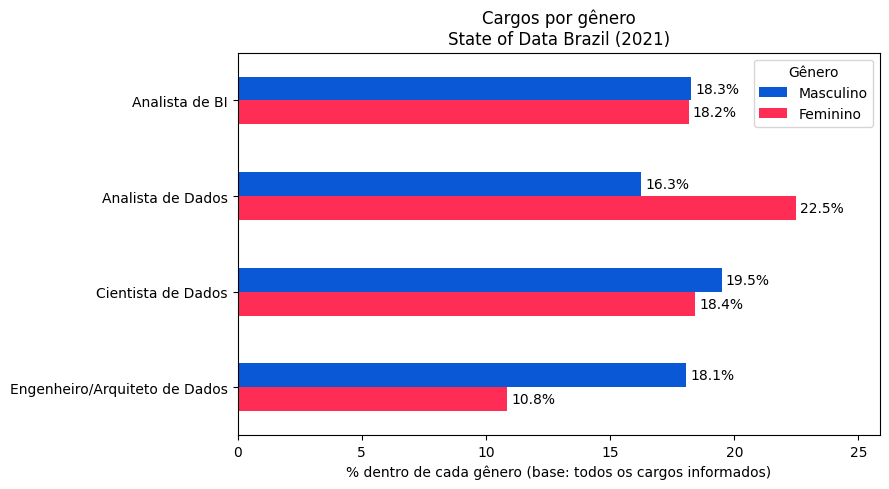

In [ ]:
def grafico_cargos(df, ano):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])].dropna(subset=["Cargo_grupo"])
    pct = pd.crosstab(d["Cargo_grupo"], d["Genero"], normalize="columns") * 100
    pct = pct.reindex(ORDEM_CARGOS).fillna(0)

    ax = pct[["Masculino", "Feminino"]].plot(kind="barh", figsize=(9, 5),
                                            color=[CORES["Masculino"], CORES["Feminino"]])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3)
    ax.set_xlim(0, pct.to_numpy().max() * 1.15)
    ax.set_xlabel("% dentro de cada gênero (base: todos os cargos informados)")
    ax.set_ylabel("")
    ax.set_title(f"Cargos por gênero\nState of Data Brazil ({ano})")
    ax.invert_yaxis()
    ax.legend(title="Gênero")
    plt.tight_layout()
    plt.savefig(f"grafico2_cargos_{ano}.png", dpi=200, bbox_inches="tight")
    plt.show()

grafico_cargos(dados[2021], 2021)

## Tabela — Tamanho dos grupos (pessoas por cargo e gênero)

In [ ]:
def tabela_n(df):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])].dropna(subset=["Cargo_grupo"])
    n = d.groupby(["Cargo_grupo", "Genero"]).size().unstack().reindex(ORDEM_CARGOS + ["Outros"])
    n["Total"] = n.sum(axis=1)
    return n

tabela_n(dados[2021])

Genero,Feminino,Masculino,Total
Cargo_grupo,,,
Analista de BI,67,271,338
Analista de Dados,83,241,324
Cientista de Dados,68,289,357
Engenheiro/Arquiteto de Dados,40,268,308
Outros,111,414,525


## Gráfico 3 — Salário médio por cargo e gênero

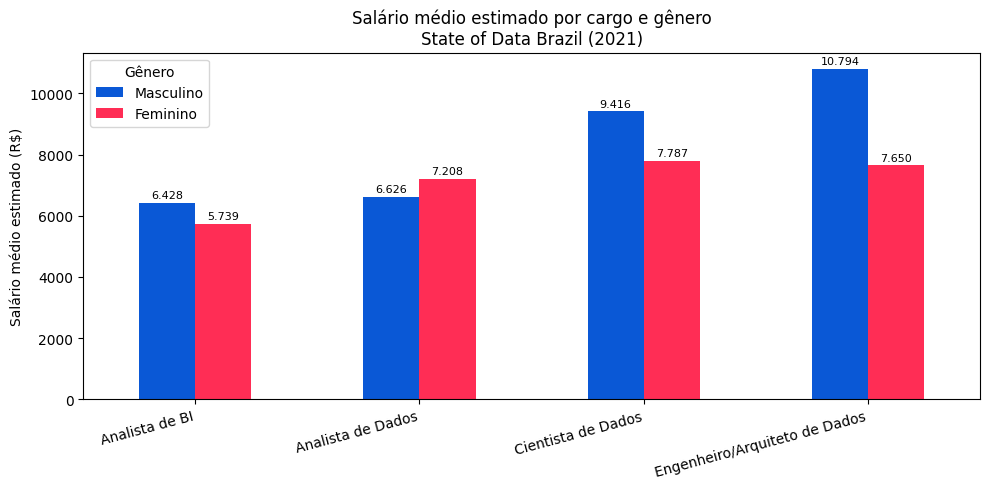

In [ ]:
def grafico_salario_cargo(df, ano):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])].dropna(subset=["Cargo_grupo"])
    d = d[d["Cargo_grupo"].isin(ORDEM_CARGOS)]
    med = d.groupby(["Cargo_grupo", "Genero"])["Salario_estimado"].mean().unstack().reindex(ORDEM_CARGOS)

    ax = med[["Masculino", "Feminino"]].plot(kind="bar", figsize=(10, 5),
                                            color=[CORES["Masculino"], CORES["Feminino"]])
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{b.get_height():,.0f}".replace(",", ".") for b in c], fontsize=8, padding=2)
    ax.set_xlabel("")
    ax.set_ylabel("Salário médio estimado (R$)")
    ax.set_title(f"Salário médio estimado por cargo e gênero\nState of Data Brazil ({ano})")
    ax.legend(title="Gênero")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(f"grafico3_salario_cargo_{ano}.png", dpi=200, bbox_inches="tight")
    plt.show()

grafico_salario_cargo(dados[2021], 2021)

## Conclusões — State of Data Brazil, edição 2021

- **Amostra:** 2.645 respondentes. Entre quem se identificou como feminino ou masculino (2.637), 18,7% são mulheres.
- **Remuneração:** com o salário estimado pelo ponto médio de cada faixa, a média das mulheres (R\$ 8.067) ficou 17,1% abaixo da dos homens (R\$ 9.736), entre quem informou a faixa salarial.
- **Cargos:** as mulheres estão proporcionalmente mais concentradas em Analista de Dados (22,5% das mulheres contra 16,3% dos homens) e menos em Engenharia/Arquitetura de Dados (10,8% contra 18,1%). Em Cientista de Dados e Analista de BI, as proporções são próximas.
- **Limites:** os resultados descrevem a amostra de 2021, de resposta voluntária, e não toda a população de profissionais de dados. O salário é uma estimativa por faixa, e a análise descreve diferenças sem investigar suas causas.
- **Próximos passos:** repetir o processo para 2022 a 2025 e comparar com o Código Fonte TV.

## Edição 2022

In [ ]:
dados[2022] = carregar_edicao(2022, col_genero="Genero", col_cargo="Cargo Atual", col_faixa="Faixa salarial", col_nivel="Nivel")

Edição 2022: 4271 linhas, 356 colunas
Gênero: {'Masculino': 3194, 'Feminino': 1056, 'Prefiro não informar': 12, nan: 9}
Faixa salarial informada: 3694 | convertida em salário: 3694
Todas as faixas informadas foram reconhecidas.


In [ ]:
de_para_2022 = dados[2022].groupby(["Cargo_grupo", "Cargo"], dropna=False).size().rename("n").reset_index(); de_para_2022

,Cargo_grupo,Cargo,n
0,Analista de BI,Analista de BI/BI Analyst,378
1,Analista de BI,Analytics Engineer,70
2,Analista de Dados,Analista de Dados/Data Analyst,639
3,Cientista de Dados,Cientista de Dados/Data Scientist,556
4,Engenheiro/Arquiteto de Dados,Engenheiro de Dados/Arquiteto de Dados/Data En...,490
5,Outros,Analista de Inteligência de Mercado/Market Int...,29
6,Outros,Analista de Marketing,19
7,Outros,Analista de Negócios/Business Analyst,123
8,Outros,Analista de Suporte/Analista Técnico,72
9,Outros,DBA/Administrador de Banco de Dados,12


In [ ]:
tabela = pd.DataFrame([resumo(dados[a]) for a in dados]).set_index("Ano"); tabela.index = tabela.index.astype(int); tabela

,Respondentes,Mulheres (%),Média salarial F,Média salarial M,Diferença (%),n com salário F,n com salário M
Ano,,,,,,,
2021,2645.0,18.7,8067.0,9736.0,17.1,436.0,1924.0
2022,4271.0,24.8,8308.0,10257.0,19.0,886.0,2790.0


## Gráfico 1 — Salário médio estimado por gênero (2022)

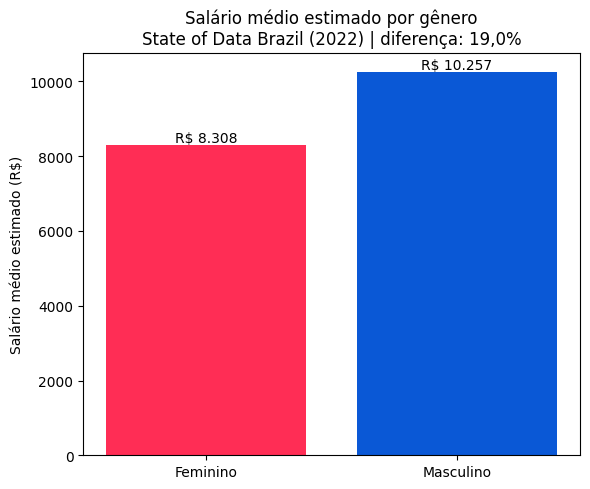

In [ ]:
grafico_salario(dados[2022], 2022)

## Gráfico 2 — Cargos por gênero (2022)

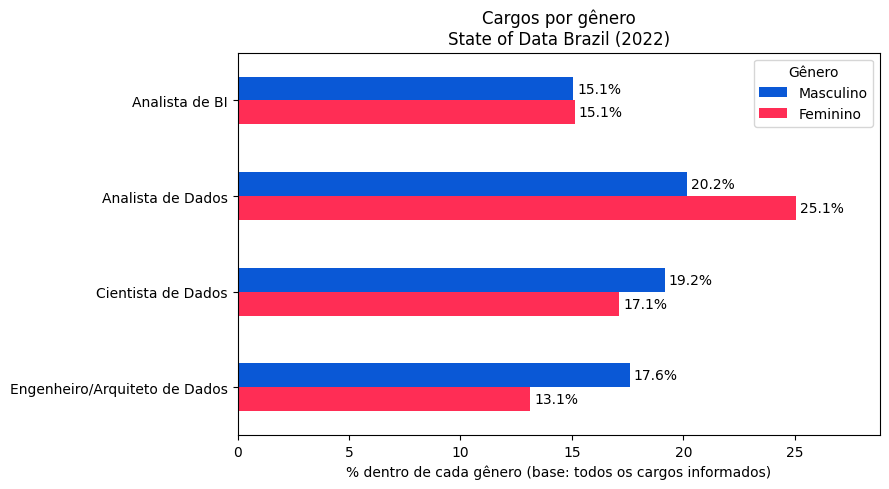

In [ ]:
grafico_cargos(dados[2022], 2022)

## Tabela — Tamanho dos grupos, pessoas por cargo e gênero (2022)

In [ ]:
tabela_n(dados[2022])

Genero,Feminino,Masculino,Total
Cargo_grupo,,,
Analista de BI,114,333,447
Analista de Dados,189,446,635
Cientista de Dados,129,424,553
Engenheiro/Arquiteto de Dados,99,389,488
Outros,223,620,843


## Gráfico 3 — Salário médio por cargo e gênero (2022)

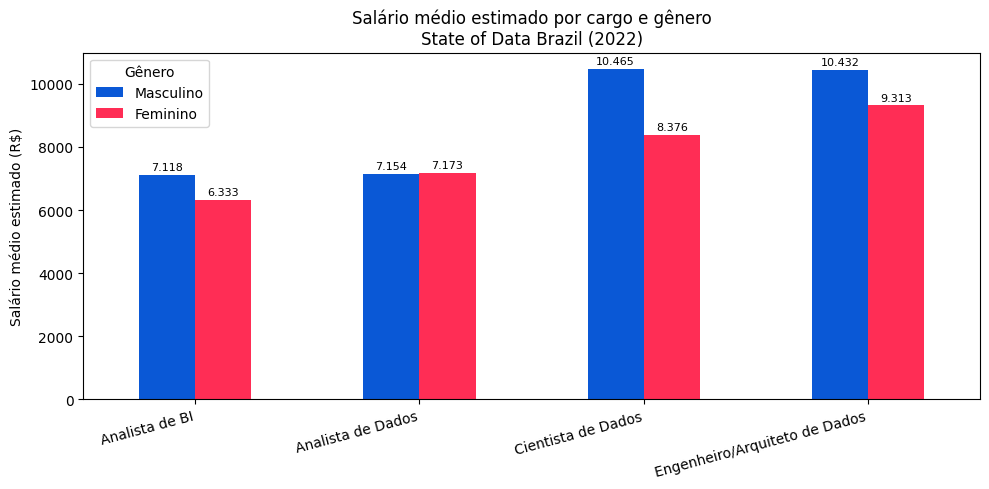

In [ ]:
grafico_salario_cargo(dados[2022], 2022)

## Conclusões — State of Data Brazil, edição 2022

* Amostra: 4.271 respondentes. Entre quem se identificou como feminino ou masculino (4.250), 24,8% são mulheres.
* Remuneração: com o salário estimado pelo ponto médio de cada faixa, a média das mulheres (R\$ 8.308) ficou 19,0% abaixo da dos homens (R\$ 10.257), entre quem informou a faixa salarial.
* Cargos: as mulheres estão proporcionalmente mais concentradas em Analista de Dados (25,1% das mulheres contra 20,2% dos homens) e menos em Engenharia/Arquitetura de Dados (13,1% contra 17,6%). Em Cientista de Dados (17,1% contra 19,2%) as proporções são mais próximas, e em Analista de BI são iguais (15,1%).
* Limites: os resultados descrevem a amostra de 2022, de resposta voluntária, e não toda a população de profissionais de dados. O salário é uma estimativa por faixa, e a análise descreve diferenças sem investigar suas causas.
* Próximos passos: repetir o processo para 2023 a 2025 e comparar com o Código Fonte TV.

## Edição 2023

In [ ]:
dados[2023] = carregar_edicao(2023, col_genero="Genero", col_cargo="Cargo Atual", col_faixa="Faixa salarial", col_nivel="Nivel")

Edição 2023: 5293 linhas, 402 colunas
Gênero: {'Masculino': 3975, 'Feminino': 1293, 'Prefiro não informar': 16, 'Outro': 9}
Faixa salarial informada: 4753 | convertida em salário: 4753
Todas as faixas informadas foram reconhecidas.


In [ ]:
de_para_2023 = dados[2023].groupby(["Cargo_grupo", "Cargo"], dropna=False).size().rename("n").reset_index(); de_para_2023

,Cargo_grupo,Cargo,n
0,Analista de BI,Analista de BI/BI Analyst,506
1,Analista de BI,Analytics Engineer,139
2,Analista de Dados,Analista de Dados/Data Analyst,907
3,Cientista de Dados,Cientista de Dados/Data Scientist,687
4,Engenheiro/Arquiteto de Dados,Engenheiro de Dados/Arquiteto de Dados/Data En...,684
5,Outros,Analista de Inteligência de Mercado/Market Int...,39
6,Outros,Analista de Negócios/Business Analyst,195
7,Outros,Analista de Suporte/Analista Técnico,72
8,Outros,DBA/Administrador de Banco de Dados,20
9,Outros,Data Product Manager/ Product Manager (PM/APM/...,81


### Gráfico 1 — Salário médio estimado por gênero (2023)

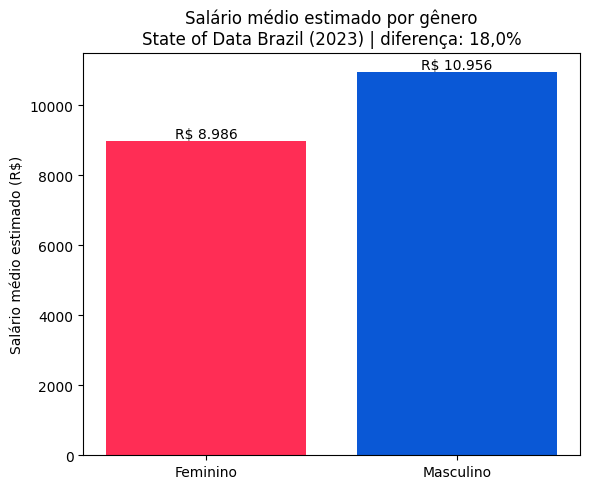

In [ ]:
grafico_salario(dados[2023], 2023)

### Gráfico 2 — Cargos por gênero (2023)

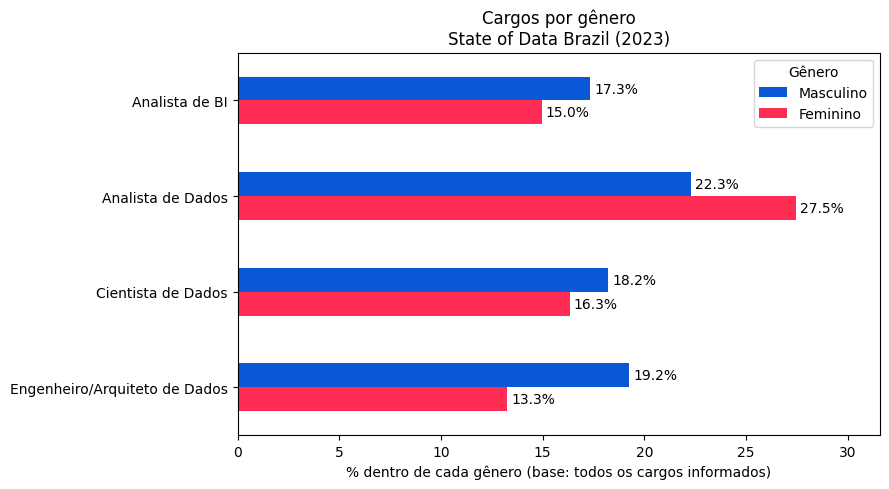

In [ ]:
grafico_cargos(dados[2023], 2023)

### Tabela — Tamanho dos grupos (n) por gênero (2023)

In [ ]:
tabela_n(dados[2023])

Genero,Feminino,Masculino,Total
Cargo_grupo,,,
Analista de BI,141,502,643
Analista de Dados,259,645,904
Cientista de Dados,154,528,682
Engenheiro/Arquiteto de Dados,125,557,682
Outros,264,664,928


### Gráfico 3 — Salário médio estimado por cargo e gênero (2023)

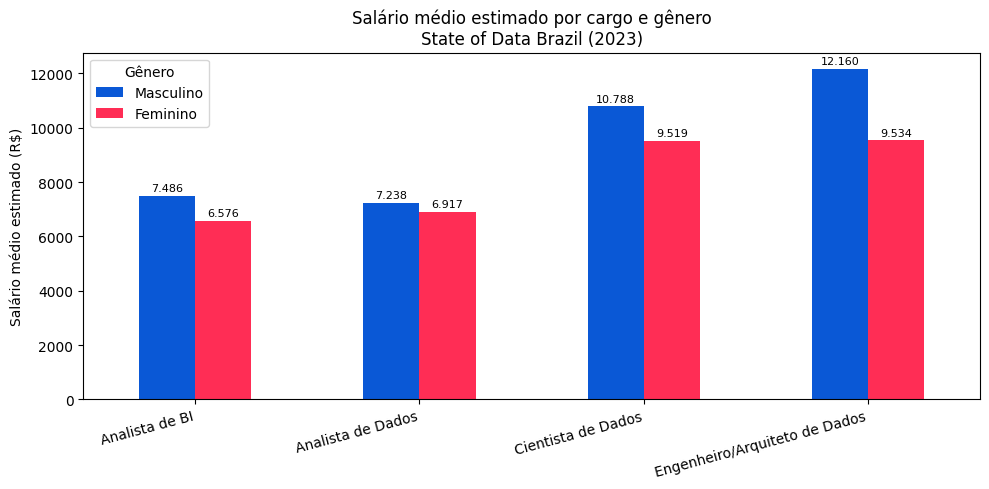

In [ ]:
grafico_salario_cargo(dados[2023], 2023)

## Conclusões — State of Data Brazil, edição 2023

* Amostra: 5.293 respondentes. Entre quem se identificou como feminino ou masculino (5.268), 24,5% são mulheres.
* Remuneração: com o salário estimado pelo ponto médio de cada faixa, a média das mulheres (R\$ 8.986) ficou 18,0% abaixo da dos homens (R\$ 10.956), entre quem informou a faixa salarial.
* Cargos: as mulheres estão proporcionalmente mais concentradas em Analista de Dados (27,5% das mulheres contra 22,3% dos homens) e menos em Engenharia/Arquitetura de Dados (13,3% contra 19,2%). Em Cientista de Dados (16,3% contra 18,2%) e Analista de BI (15,0% contra 17,3%), as proporções são mais próximas.
* Limites: os resultados descrevem a amostra de 2023, de resposta voluntária, e não toda a população de profissionais de dados. O salário é uma estimativa por faixa, e a análise descreve diferenças sem investigar suas causas.
* Próximos passos: repetir o processo para 2024 e 2025 e comparar com o Código Fonte TV.

## Edição 2024

In [ ]:
dados[2024] = carregar_edicao(2024, col_genero="1.b_genero", col_cargo="2.f_cargo_atual", col_faixa="2.h_faixa_salarial", col_nivel="2.g_nivel")

Edição 2024: 5217 linhas, 406 colunas
Gênero: {'Masculino': 3968, 'Feminino': 1226, 'Prefiro não informar': 15, 'Outro': 8}
Faixa salarial informada: 4863 | convertida em salário: 4863
Todas as faixas informadas foram reconhecidas.


In [ ]:
de_para_2024 = dados[2024].groupby(["Cargo_grupo", "Cargo"], dropna=False).size().rename("n").reset_index(); de_para_2024

,Cargo_grupo,Cargo,n
0,Analista de BI,Analista de BI/BI Analyst,396
1,Analista de BI,Analytics Engineer,228
2,Analista de Dados,Analista de Dados/Data Analyst,957
3,Cientista de Dados,Cientista de Dados/Data Scientist,687
4,Engenheiro/Arquiteto de Dados,Arquiteto de Dados/Data Architect,48
5,Engenheiro/Arquiteto de Dados,Engenheiro de Dados/Data Engineer/Data Architect,613
6,Outros,Analista de Negócios/Business Analyst,184
7,Outros,Analista de Suporte/Analista Técnico,79
8,Outros,Data Product Manager/ Product Manager (PM/APM/...,80
9,Outros,Desenvolvedor/ Engenheiro de Software/ Analist...,122


### Gráfico 1 — Salário médio estimado por gênero (2024)

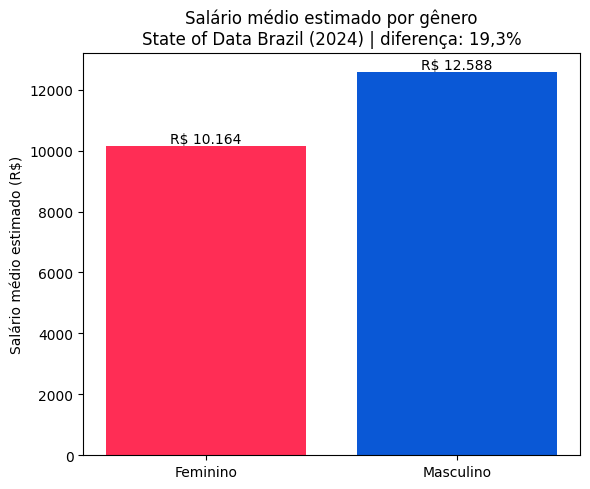

In [ ]:
grafico_salario(dados[2024], 2024)

### Gráfico 2 — Cargos por gênero (2024)

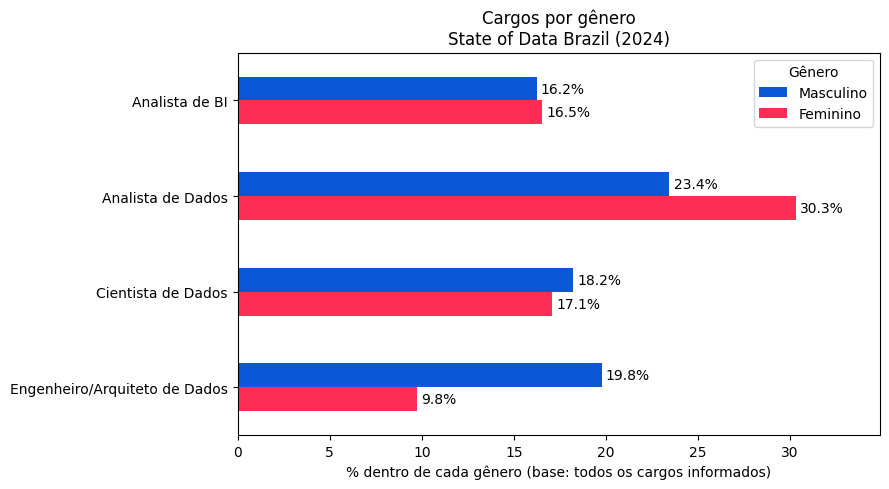

In [ ]:
grafico_cargos(dados[2024], 2024)

### Tabela — Tamanho dos grupos (n) por gênero (2024)

In [ ]:
tabela_n(dados[2024])

Genero,Feminino,Masculino,Total
Cargo_grupo,,,
Analista de BI,156,464,620
Analista de Dados,286,670,956
Cientista de Dados,161,521,682
Engenheiro/Arquiteto de Dados,92,565,657
Outros,248,638,886


### Gráfico 3 — Salário médio estimado por cargo e gênero (2024)

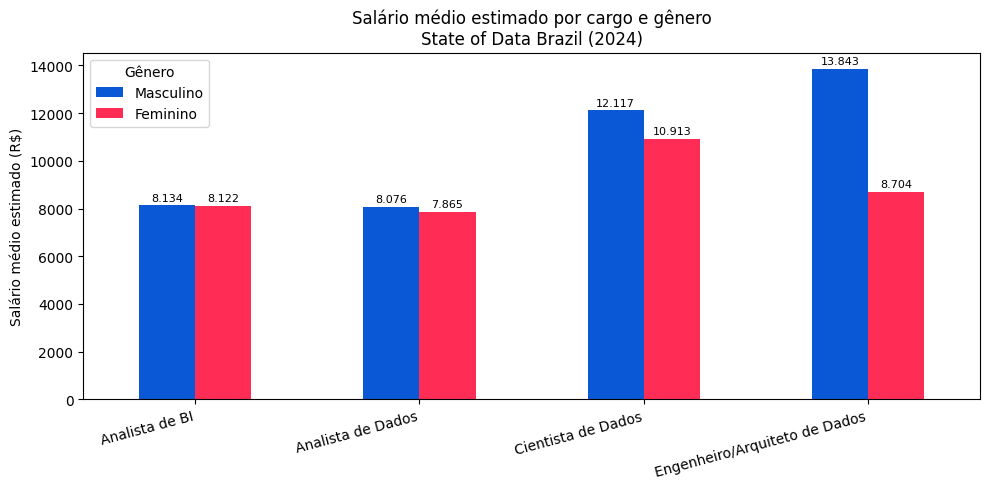

In [ ]:
grafico_salario_cargo(dados[2024], 2024)

## Conclusões — State of Data Brazil, edição 2024

* Amostra: 5.217 respondentes. Entre quem se identificou como feminino ou masculino (5.194), 23,6% são mulheres.
* Remuneração: com o salário estimado pelo ponto médio de cada faixa, a média das mulheres (R\$ 10.164) ficou 19,3% abaixo da dos homens (R\$ 12.588), entre quem informou a faixa salarial.
* Cargos: as mulheres estão proporcionalmente mais concentradas em Analista de Dados (30,3% das mulheres contra 23,4% dos homens) e menos em Engenharia/Arquitetura de Dados (9,8% contra 19,8%). Em Cientista de Dados e Analista de BI, as proporções são próximas.
* Limites: os resultados descrevem a amostra de 2024, de resposta voluntária, e não toda a população de profissionais de dados. O salário é uma estimativa por faixa, e a análise descreve diferenças sem investigar suas causas.
* Próximos passos: repetir o processo para 2025 e comparar com o Código Fonte TV.

## Edição 2025

In [ ]:
dados[2025] = carregar_edicao(2025, col_genero="1.b_genero", col_cargo="2.f_cargo_atual", col_faixa="2.h_faixa_salarial", col_nivel="2.g_nivel")

Edição 2025: 3495 linhas, 391 colunas
Gênero: {'Masculino': 2707, 'Feminino': 768, 'Prefiro não informar': 13, 'Outro': 7}
Faixa salarial informada: 3228 | convertida em salário: 3228
Todas as faixas informadas foram reconhecidas.


In [ ]:
de_para_2025 = dados[2025].groupby(["Cargo_grupo", "Cargo"], dropna=False).size().rename("n").reset_index(); de_para_2025

,Cargo_grupo,Cargo,n
0,Analista de BI,Analista de BI/BI Analyst,215
1,Analista de BI,Analytics Engineer,135
2,Analista de Dados,Analista de Dados/Data Analyst,599
3,Cientista de Dados,Cientista de Dados/Data Scientist,424
4,Engenheiro/Arquiteto de Dados,Arquiteto de Dados/Data Architect,28
5,Engenheiro/Arquiteto de Dados,Engenheiro de Dados/Data Engineer/Data Architect,402
6,Outros,Analista de Negócios/Business Analyst,141
7,Outros,Analista de Suporte/Analista Técnico,55
8,Outros,Data Product Manager/ Product Manager (PM/APM/...,33
9,Outros,Desenvolvedor/ Engenheiro de Software/ Analist...,106


### Gráfico 1 — Salário médio estimado por gênero (2025)

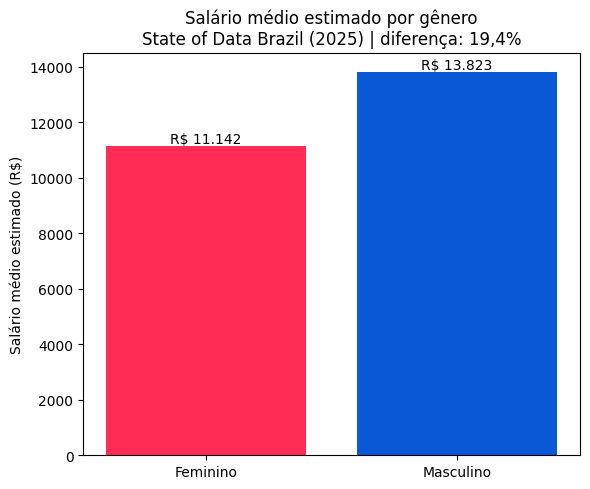

In [ ]:
grafico_salario(dados[2025], 2025)

### Gráfico 2 — Cargos por gênero (2025)

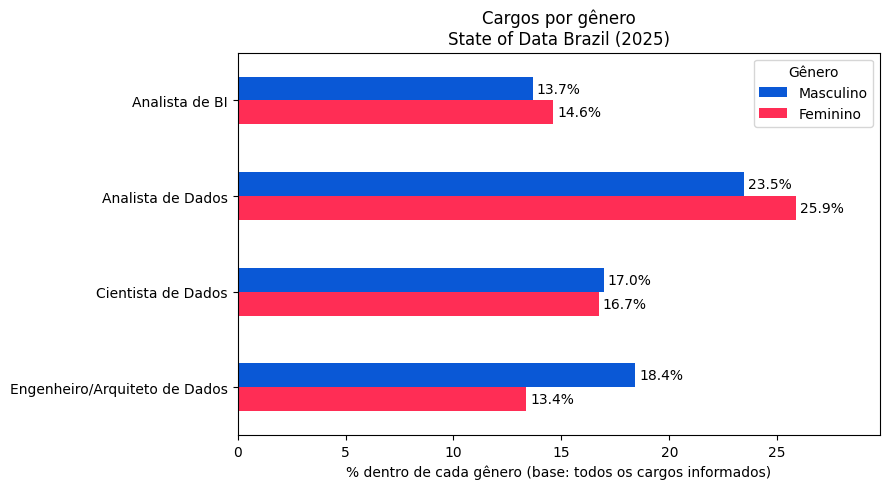

In [ ]:
grafico_cargos(dados[2025], 2025)

### Tabela — Tamanho dos grupos (n) por gênero (2025)

In [ ]:
tabela_n(dados[2025])

Genero,Feminino,Masculino,Total
Cargo_grupo,,,
Analista de BI,83,262,345
Analista de Dados,147,450,597
Cientista de Dados,95,325,420
Engenheiro/Arquiteto de Dados,76,353,429
Outros,167,527,694


### Gráfico 3 — Salário médio estimado por cargo e gênero (2025)

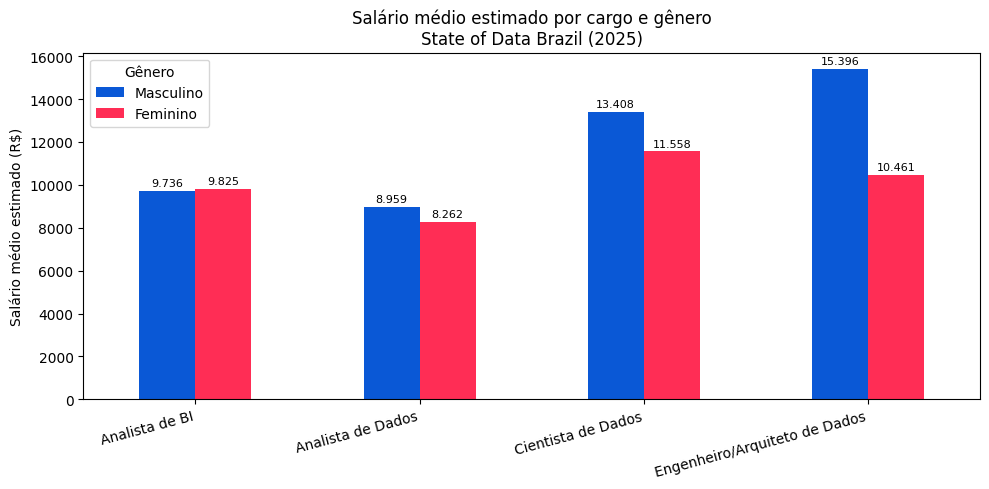

In [ ]:
grafico_salario_cargo(dados[2025], 2025)

## Conclusões — State of Data Brazil, edição 2025

* Amostra: 3.495 respondentes. Entre quem se identificou como feminino ou masculino (3.475), 22,1% são mulheres.
* Remuneração: com o salário estimado pelo ponto médio de cada faixa, a média das mulheres (R\$ 11.142) ficou 19,4% abaixo da dos homens (R\$ 13.823), entre quem informou a faixa salarial.
* Cargos: as mulheres estão proporcionalmente mais concentradas em Analista de Dados (25,9% das mulheres contra 23,5% dos homens) e menos em Engenharia/Arquitetura de Dados (13,4% contra 18,4%). Em Cientista de Dados e Analista de BI, as proporções são próximas.
* Limites: os resultados descrevem a amostra de 2025, de resposta voluntária, e não toda a população de profissionais de dados. O salário é uma estimativa por faixa, e a análise descreve diferenças sem investigar suas causas.
* Próximos passos: comparar os cinco anos entre si e com o Código Fonte TV.

## Resumo comparativo 2021–2025

In [ ]:
tabela = pd.DataFrame([resumo(dados[a]) for a in dados]).set_index("Ano")
tabela.index = tabela.index.astype(int)
tabela

,Respondentes,Mulheres (%),Média salarial F,Média salarial M,Diferença (%),n com salário F,n com salário M
Ano,,,,,,,
2021,2645.0,18.7,8067.0,9736.0,17.1,436.0,1924.0
2022,4271.0,24.8,8308.0,10257.0,19.0,886.0,2790.0
2023,5293.0,24.5,8986.0,10956.0,18.0,1111.0,3622.0
2024,5217.0,23.6,10164.0,12588.0,19.3,1142.0,3700.0
2025,3495.0,22.1,11142.0,13823.0,19.4,702.0,2510.0


### Gráfico — Percentual de mulheres, 2021–2025

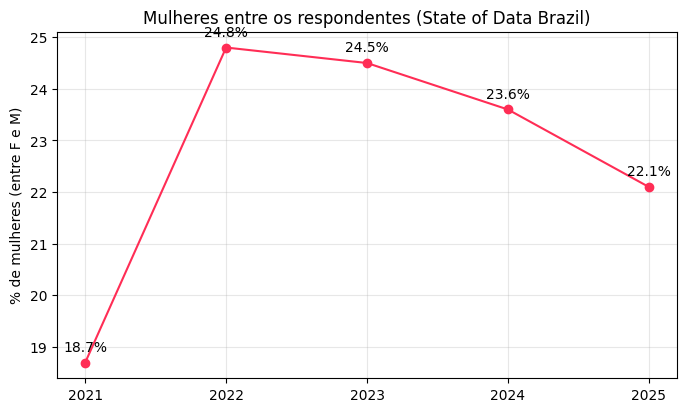

In [ ]:
plt.figure(figsize=(8,4.5))
plt.plot(tabela.index, tabela["Mulheres (%)"], marker="o", color="#FF2D55")
for x, y in tabela["Mulheres (%)"].items(): plt.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(0,8), ha="center")
plt.title("Mulheres entre os respondentes (State of Data Brazil)")
plt.ylabel("% de mulheres (entre F e M)"); plt.xticks(tabela.index); plt.grid(alpha=.3); plt.show()

### Gráfico — Salário médio estimado por gênero, 2021–2025

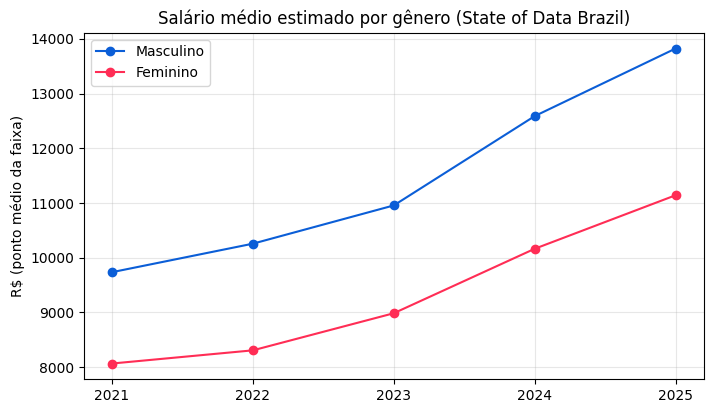

In [ ]:
plt.figure(figsize=(8,4.5))
plt.plot(tabela.index, tabela["Média salarial M"], marker="o", color="#0B5ED7", label="Masculino")
plt.plot(tabela.index, tabela["Média salarial F"], marker="o", color="#FF2D55", label="Feminino")
plt.title("Salário médio estimado por gênero (State of Data Brazil)")
plt.ylabel("R$ (ponto médio da faixa)"); plt.xticks(tabela.index); plt.legend(); plt.grid(alpha=.3); plt.show()

### Gráfico — Diferença salarial (%) entre homens e mulheres, 2021–2025

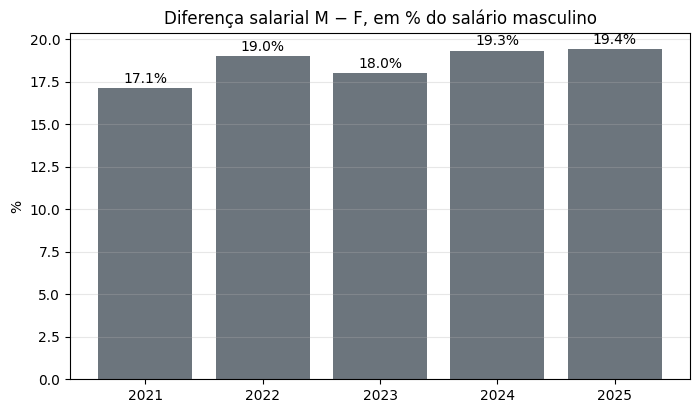

In [ ]:
plt.figure(figsize=(8,4.5))
plt.bar(tabela.index, tabela["Diferença (%)"], color="#6C757D")
for x, y in tabela["Diferença (%)"].items(): plt.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(0,4), ha="center")
plt.title("Diferença salarial M − F, em % do salário masculino")
plt.ylabel("%"); plt.xticks(tabela.index); plt.grid(alpha=.3, axis="y"); plt.show()

## Comparação estatística da diferença salarial (Objetivo 4)

In [ ]:
from scipy import stats
import numpy as np

rng = np.random.default_rng(42)  # semente fixa: resultado reprodutivel

def teste_ano(df, ano, n_boot=5000):
    d = df[df["Genero"].isin(["Feminino", "Masculino"])].dropna(subset=["Salario_estimado"])
    f = d.loc[d["Genero"] == "Feminino", "Salario_estimado"].to_numpy()
    m = d.loc[d["Genero"] == "Masculino", "Salario_estimado"].to_numpy()
    welch = stats.ttest_ind(m, f, equal_var=False)
    mw = stats.mannwhitneyu(m, f, alternative="two-sided")
    boot = np.array([rng.choice(m, len(m)).mean() - rng.choice(f, len(f)).mean() for _ in range(n_boot)])
    ic_inf, ic_sup = np.percentile(boot, [2.5, 97.5])
    dp = np.sqrt(((len(m)-1)*m.var(ddof=1) + (len(f)-1)*f.var(ddof=1)) / (len(m)+len(f)-2))
    return {"Ano": ano, "n F": len(f), "n M": len(m),
            "Diferenca (R$)": round(m.mean() - f.mean()),
            "IC95% inf": round(ic_inf), "IC95% sup": round(ic_sup),
            "p (Welch)": welch.pvalue, "p (Mann-Whitney)": mw.pvalue,
            "d de Cohen": round((m.mean() - f.mean()) / dp, 2)}

testes = pd.DataFrame([teste_ano(dados[a], a) for a in dados]).set_index("Ano")
testes.style.format({"p (Welch)": "{:.2e}", "p (Mann-Whitney)": "{:.2e}"})

,n F,n M,Diferenca (R$),IC95% inf,IC95% sup,p (Welch),p (Mann-Whitney),d de Cohen
Ano,,,,,,,,
2021,436,1924,1669,967,2350,2.15e-06,3.48e-04,0.220000
2022,886,2790,1949,1449,2456,8.28e-14,1.23e-07,0.250000
2023,1111,3622,1969,1483,2467,3.69e-15,1.39e-11,0.240000
2024,1142,3700,2424,1908,2930,7.31e-20,3.74e-13,0.270000
2025,702,2510,2681,1979,3412,3.18e-13,2.28e-08,0.270000


### Gráfico — Diferença salarial M − F com intervalo de confiança de 95%

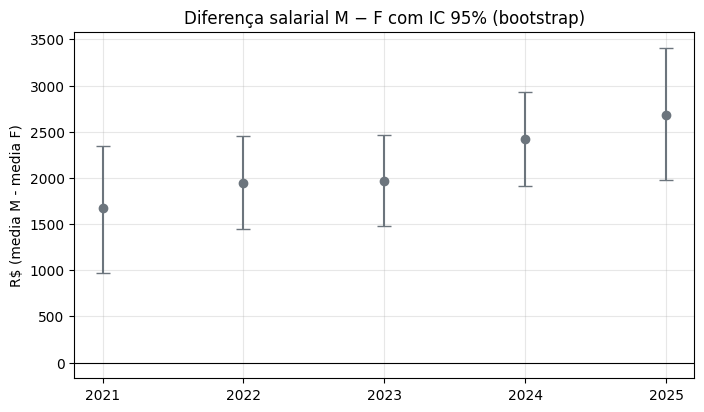

In [ ]:
plt.figure(figsize=(8, 4.5))
y = testes["Diferenca (R$)"]
err = [y - testes["IC95% inf"], testes["IC95% sup"] - y]
plt.errorbar(testes.index, y, yerr=err, fmt="o", capsize=5, color="#6C757D")
plt.axhline(0, color="black", lw=.8)
plt.title("Diferença salarial M − F com IC 95% (bootstrap)")
plt.ylabel("R$ (media M - media F)"); plt.xticks(testes.index); plt.grid(alpha=.3); plt.show()

### Teste da variação da lacuna salarial entre 2021 e 2025

In [ ]:
def amostra(ano):
    d = dados[ano]
    d = d[d["Genero"].isin(["Feminino", "Masculino"])]
    s = d.dropna(subset=["Salario_estimado"])
    m = s.loc[s["Genero"] == "Masculino", "Salario_estimado"].to_numpy()
    f = s.loc[s["Genero"] == "Feminino", "Salario_estimado"].to_numpy()
    return m, f, int((d["Genero"] == "Feminino").sum()), int((d["Genero"] == "Masculino").sum())

def lacuna(m, f):
    return (m.mean() - f.mean()) / m.mean() * 100

def comparar_anos(a1, a2, n_boot=5000):
    m1, f1, nf1, nm1 = amostra(a1)
    m2, f2, nf2, nm2 = amostra(a2)
    obs = lacuna(m2, f2) - lacuna(m1, f1)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        b = [rng.choice(x, len(x)) for x in (m1, f1, m2, f2)]
        boot[i] = lacuna(b[2], b[3]) - lacuna(b[0], b[1])
    ic = np.percentile(boot, [2.5, 97.5])
    p_boot = min(1, 2 * min((boot >= 0).mean(), (boot <= 0).mean()))
    chi2, p_prop, _, _ = stats.chi2_contingency([[nf1, nm1], [nf2, nm2]])
    return pd.Series({
        "Lacuna salarial " + str(a1) + " (%)": round(lacuna(m1, f1), 1),
        "Lacuna salarial " + str(a2) + " (%)": round(lacuna(m2, f2), 1),
        "Variacao (pontos percentuais)": round(obs, 1),
        "IC95% inf": round(ic[0], 1), "IC95% sup": round(ic[1], 1),
        "p (bootstrap)": round(p_boot, 3),
        "Mulheres " + str(a1) + " (%)": round(100 * nf1 / (nf1 + nm1), 1),
        "Mulheres " + str(a2) + " (%)": round(100 * nf2 / (nf2 + nm2), 1),
        "p (qui-quadrado, % mulheres)": float(p_prop)})

comparar_anos(2021, 2025).to_frame("2021 x 2025")

,2021 x 2025
Lacuna salarial 2021 (%),17.100000
Lacuna salarial 2025 (%),19.400000
Variacao (pontos percentuais),2.300000
IC95% inf,-5.700000
IC95% sup,10.500000
p (bootstrap),0.585000
Mulheres 2021 (%),18.700000
Mulheres 2025 (%),22.100000
"p (qui-quadrado, % mulheres)",0.001253


# Parte 2 — Código Fonte TV (TI em geral)

Dados da Pesquisa Salarial do Código Fonte TV, extraídos manualmente do painel de cada edição (participantes e percentual por gênero). Ver planilha de rastreabilidade.

In [ ]:
# Código Fonte TV (TI em geral): valores extraídos manualmente do painel da pesquisa (ver planilha de rastreabilidade)
# A primeira edição, rotulada 2021 no site, teve coleta de set/2020 a fev/2021
cftv = pd.DataFrame({
    "Participantes": [11441, 11521, 17818, 15049, 12510],
    "Mulheres (%)": [5.9, 7.5, 8.9, 9.2, 7.1],
    "Homens (%)": [93.8, 92.1, 90.7, 90.4, 92.6]}, index=[2021, 2022, 2023, 2024, 2025])
cftv.index.name = "Ano"
cftv

,Participantes,Mulheres (%),Homens (%)
Ano,,,
2021,11441,5.9,93.8
2022,11521,7.5,92.1
2023,17818,8.9,90.7
2024,15049,9.2,90.4
2025,12510,7.1,92.6


### Remuneração por gênero no Código Fonte TV (extraída dos gráficos do painel)

O painel de cada edição traz um gráfico de barras por faixa salarial para cada gênero. A altura de cada barra foi medida na imagem do gráfico; como ela é proporcional ao número de pessoas, usa-se a distribuição percentual dentro de cada gênero. O método reproduz, por exemplo, o dado que o próprio painel de 2021 informa (cerca de 18% dos homens e 6,7% das mulheres acima de R\$ 9.000). O salário estimado usa o ponto médio de cada faixa; a faixa aberta (acima de R\$ 20.000) usa R\$ 25.000, e a tabela mostra como a lacuna muda com 20 mil e 30 mil.

In [ ]:
# Altura (em pixels) de cada barra dos gráficos "Participantes por gênero" do painel de cada edição.
# A altura é proporcional ao número de participantes da faixa; o que se usa é a distribuição percentual dentro de cada gênero.
# Edição 2021: 12 faixas (última: acima de R$ 20.000). Edições 2022 a 2025: 15 faixas.
barras = {
    "M": {2021: [100,278,265,202,178,142,120,174,153,79,51,40],
          2022: [45,199,233,235,205,185,153,241,262,149,102,59,26,11,10],
          2023: [32,147,188,207,177,148,134,241,252,156,122,74,29,14,12],
          2024: [29,125,175,201,173,136,143,236,267,165,139,97,28,11,12],
          2025: [9,92,152,171,174,141,135,229,288,201,159,105,36,14,17]},
    "F": {2021: [90,262,260,170,198,106,82,98,37,23,15,13],
          2022: [23,238,272,200,248,222,122,176,126,39,27,19,3,5,3],
          2023: [45,253,247,255,226,179,171,211,157,65,49,27,7,4,4],
          2024: [31,189,202,244,214,140,129,198,156,61,52,26,10,1,7],
          2025: [11,144,238,190,200,158,144,250,222,98,65,43,11,1,1]}}

# 12 faixas comparáveis: nas edicoes de 15 faixas, as quatro últimas (acima de R$ 20.000) são somadas
FAIXAS = ["Menos de 1.000", "1.001-2.000", "2.001-3.000", "3.001-4.000", "4.001-5.000", "5.001-6.000",
          "6.001-7.000", "7.001-9.000", "9.001-12.000", "12.001-15.000", "15.001-20.000", "Acima de 20.000"]

def distribuicao(alturas):
    a = np.array(alturas, dtype=float)
    if len(a) == 15:
        a = np.append(a[:11], a[11:].sum())
    return a / a.sum() * 100

dist = {(g, ano): distribuicao(v) for g in barras for ano, v in barras[g].items()}

def lacuna_cftv(ano, topo=25000):
    # ponto médio das faixas; a faixa aberta (acima de R$ 20.000) usa o valor 'topo'
    pm = np.array([500, 1500, 2500, 3500, 4500, 5500, 6500, 8000, 10500, 13500, 17500, topo], dtype=float)
    mm = (dist[("M", ano)] / 100 * pm).sum()
    mf = (dist[("F", ano)] / 100 * pm).sum()
    return mm, mf, (mm - mf) / mm * 100

linhas = []
for ano in range(2021, 2026):
    mm, mf, lac = lacuna_cftv(ano)
    linhas.append({"Ano": ano,
                   "Média estimada M (R$)": round(mm), "Média estimada F (R$)": round(mf),
                   "Lacuna (%)": round(lac, 1),
                   "Lacuna, faixa aberta = 20 mil (%)": round(lacuna_cftv(ano, 20000)[2], 1),
                   "Lacuna, faixa aberta = 30 mil (%)": round(lacuna_cftv(ano, 30000)[2], 1),
                   "Acima de R$ 9.000 - M (%)": round(dist[("M", ano)][8:].sum(), 1),
                   "Acima de R$ 9.000 - F (%)": round(dist[("F", ano)][8:].sum(), 1)})
cftv_sal = pd.DataFrame(linhas).set_index("Ano")
cftv_sal

,Média estimada M (R$),Média estimada F (R$),Lacuna (%),"Lacuna, faixa aberta = 20 mil (%)","Lacuna, faixa aberta = 30 mil (%)",Acima de R$ 9.000 - M (%),Acima de R$ 9.000 - F (%)
Ano,,,,,,,
2021,5699,4254,25.4,24.7,26.0,18.1,6.5
2022,7464,5432,27.2,25.9,28.5,29.3,12.9
2023,8253,5867,28.9,27.3,30.4,34.1,16.5
2024,8699,6196,28.8,27.1,30.3,37.1,18.9
2025,9469,6970,26.4,24.5,28.1,42.6,24.8


## Código Fonte TV por área de atuação (2023–2025)

O painel do Código Fonte TV permite filtrar por **área de atuação** (Back-End, Front-End, Dados, QA etc.). Com o filtro ligado, o gráfico "Participantes por gênero" mostra o percentual e a faixa salarial de homens e mulheres só daquela área. Isso permite ver **em quais áreas há mais ou menos mulheres** e se a lacuna salarial muda de uma área para outra.

**Como foi extraído:** para cada ano e área foram registrados o número de participantes, o percentual de homens e de mulheres (texto do painel) e a altura das barras do gráfico de faixas salariais (lidas por pixel, como na seção anterior). O número de homens e mulheres por faixa é **estimado** a partir dessas alturas e dos percentuais, portanto é aproximado.

**Limites:** o recorte por área só existe de 2023 a 2025. Em 2023 não há Full-Stack, RPA, SRE nem UX/UI, e Front-End aparece como "Web". Em áreas com poucas mulheres a lacuna salarial oscila muito, por isso ela só é calculada onde há pelo menos 100 mulheres.

In [ ]:
# Código Fonte TV por área de atuação, 2023–2025.
# Formato: (ano, área): (participantes, % homens, % mulheres, alturas das barras dos homens, alturas das barras das mulheres)
# As alturas (em pixels) são proporcionais ao número de pessoas em cada uma das 15 faixas salariais do painel.
# As quatro últimas faixas (acima de R$ 20.000) usam o mesmo ponto médio.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOMES = {"geral": "TI em geral", "backend": "Back-End", "banco-de-dados": "Banco de Dados", "dados": "Dados",
         "desktop": "Desktop", "devops": "DevOps", "embarcados": "Embarcados", "frontend": "Front-End",
         "web": "Front-End", "fullstack": "Full-Stack", "ux-ui": "UX/UI", "games": "Games", "iot": "IoT",
         "mobile": "Mobile", "outra": "Outra", "qa": "QA", "rpa": "RPA", "sre": "SRE",
         "seguranca-da-informacao": "Segurança da Informação"}

AREAS_CFTV = {
(2023,"geral"):(17818,90.7,8.9,[32,147,188,207,177,148,134,241,252,156,122,74,29,14,12],[45,253,247,255,226,180,171,211,157,65,49,27,7,4,4]),
(2024,"geral"):(15049,90.4,9.2,[29,125,175,201,173,136,143,236,267,165,139,97,28,11,12],[31,189,202,244,214,140,129,198,156,61,52,26,10,0,7]),
(2025,"geral"):(12510,92.6,7.1,[9,92,152,171,174,141,135,229,288,201,159,105,36,14,17],[11,144,238,190,200,158,144,250,222,98,65,43,11,1,1]),
(2023,"backend"):(5130,91.9,8,[19,102,116,160,142,121,124,239,272,196,139,75,33,14,9],[38,180,214,192,188,184,188,261,145,72,59,25,8,0,0]),
(2023,"banco-de-dados"):(230,83,16.1,[34,154,205,291,197,129,68,188,162,120,59,8,0,8,8],[60,270,120,240,120,0,90,90,29,90,0,0,0,0,0]),
(2023,"dados"):(1098,87.9,11.8,[38,143,145,146,160,130,106,205,255,100,90,59,11,3,13],[33,300,250,216,283,233,166,216,283,83,33,33,16,16,0]),
(2023,"desktop"):(469,96.4,3.6,[34,115,235,197,265,248,158,291,145,120,90,21,8,0,4],[0,225,75,75,225,150,150,300,0,75,0,0,0,0,0]),
(2023,"devops"):(459,93,6.1,[0,155,140,170,190,145,105,270,295,225,190,130,59,14,44],[50,100,200,0,300,250,100,50,200,50,0,100,0,0,0]),
(2023,"embarcados"):(128,97.7,2.3,[0,150,240,120,90,165,90,300,255,120,120,180,29,14,0],[0,300,0,0,0,0,300,300,0,0,0,0,0,0,0]),
(2023,"games"):(88,88.6,6.8,[24,175,175,175,200,125,200,300,150,24,125,100,100,75,0],[0,0,300,0,150,0,150,150,0,0,150,0,0,0,0]),
(2023,"iot"):(32,87.5,12.5,[60,240,180,240,300,120,0,240,180,0,0,60,0,0,60],[0,300,0,300,0,0,300,0,0,0,300,0,0,0,0]),
(2023,"mobile"):(1089,92.2,7.3,[43,112,164,198,184,140,190,226,264,184,165,74,19,31,9],[24,175,150,275,225,200,275,200,100,150,125,24,24,0,24]),
(2023,"outra"):(607,88.6,10.4,[64,197,223,235,188,188,129,188,270,171,223,141,38,17,29],[0,275,275,150,150,175,125,200,50,75,24,0,24,0,50]),
(2023,"qa"):(512,77,22.1,[14,185,240,295,225,185,135,190,225,100,120,19,19,4,9],[23,96,180,252,216,132,132,96,132,60,23,0,0,0,11]),
(2023,"seguranca-da-informacao"):(91,85.7,13.2,[0,275,225,150,150,275,125,150,175,75,175,125,24,0,24],[0,300,0,200,200,300,100,0,0,0,0,100,0,0,0]),
(2023,"web"):(7885,91,8.7,[43,186,254,259,202,165,147,259,251,141,104,77,31,15,13],[52,265,245,262,197,142,127,170,145,34,37,27,0,7,0]),
(2024,"backend"):(4652,91.3,8.4,[16,72,109,130,114,106,113,206,265,176,144,89,25,10,8],[8,145,192,188,210,111,192,261,192,64,59,25,8,4,8]),
(2024,"banco-de-dados"):(163,90.2,9.8,[84,96,204,228,204,108,96,120,288,156,72,72,0,11,23],[60,120,300,180,0,60,60,0,60,60,0,60,0,0,0]),
(2024,"dados"):(750,88.4,11.5,[29,138,192,143,195,165,150,228,261,168,129,135,32,5,14],[60,220,300,160,240,220,100,140,140,60,80,0,0,0,0]),
(2024,"desktop"):(268,96.3,3.7,[7,105,172,210,217,157,232,285,270,127,82,37,14,7,7],[150,150,0,150,150,150,300,300,0,0,150,0,0,0,0]),
(2024,"devops"):(258,91.9,7.8,[0,160,180,150,240,220,130,270,260,280,160,190,50,39,39],[120,300,120,120,60,60,120,120,180,0,0,0,0,0,0]),
(2024,"embarcados"):(81,95.1,4.9,[24,125,50,150,100,175,150,175,275,175,225,150,75,24,50],[300,0,0,300,300,0,300,0,0,0,0,0,0,0,0]),
(2024,"frontend"):(1793,83.8,15.7,[70,213,293,280,250,170,200,300,266,160,130,120,33,8,8],[19,170,175,265,150,130,75,155,140,54,19,29,24,0,0]),
(2024,"fullstack"):(5233,92.8,6.8,[32,157,218,258,204,143,144,251,268,137,122,90,29,12,11],[39,235,220,255,240,200,110,215,100,64,64,4,4,0,19]),
(2024,"games"):(58,96.6,3.4,[0,187,225,112,37,112,262,187,300,187,112,225,112,37,0],[0,0,0,0,0,0,300,0,300,0,0,0,0,0,0]),
(2024,"iot"):(22,100,0,[0,300,60,120,120,180,120,60,60,60,180,0,0,60,0],[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]),
(2024,"mobile"):(848,90.6,9.3,[24,90,92,190,177,135,177,252,247,202,177,97,22,14,17],[16,50,83,266,133,100,116,116,200,83,83,66,0,0,0]),
(2024,"outra"):(352,86.6,12.8,[52,172,195,217,150,172,127,180,285,225,285,120,37,22,44],[29,180,180,180,300,60,90,60,90,29,60,60,29,0,0]),
(2024,"qa"):(293,75.1,24.2,[51,137,223,265,205,145,171,214,180,102,68,68,34,8,8],[16,133,116,266,283,50,50,133,116,16,0,0,0,0,0]),
(2024,"rpa"):(138,89.1,10.9,[23,84,276,252,216,168,120,120,120,96,0,0,0,0,0],[0,300,150,225,75,0,75,75,150,75,0,0,0,0,0]),
(2024,"seguranca-da-informacao"):(64,82.8,17.2,[37,187,112,300,187,112,187,150,300,75,300,0,37,0,0],[100,300,300,0,0,0,0,0,100,0,100,200,0,0,0]),
(2024,"sre"):(76,97.4,2.6,[0,19,39,60,39,39,120,160,180,280,200,200,80,0,60],[0,0,0,0,300,0,0,300,0,0,0,0,0,0,0]),
(2025,"backend"):(3760,93,6.8,[0,48,89,102,108,93,95,179,269,192,166,90,32,12,13],[11,72,161,132,186,102,102,294,264,96,78,17,11,0,0]),
(2025,"banco-de-dados"):(124,91.1,8.9,[0,108,132,108,96,132,47,192,252,108,120,23,35,0,0],[0,100,300,100,200,200,0,100,100,0,0,0,0,0,0]),
(2025,"dados"):(682,91.3,8.5,[5,120,135,186,189,105,138,252,267,183,132,102,35,0,17],[24,150,50,125,125,300,50,200,250,50,50,50,0,24,0]),
(2025,"desktop"):(181,95,5,[9,80,90,100,290,240,110,250,240,140,90,39,19,0,19],[0,200,100,300,0,0,100,200,0,0,0,0,0,0,0]),
(2025,"devops"):(240,93.8,6.3,[5,41,65,102,138,65,96,132,264,144,102,108,23,17,41],[0,300,200,100,200,0,100,300,100,200,0,0,0,0,0]),
(2025,"embarcados"):(76,98.7,1.3,[19,19,60,80,60,60,80,280,300,160,80,180,80,39,0],[0,0,0,300,0,0,0,0,0,0,0,0,0,0,0]),
(2025,"frontend"):(1133,86.3,13.2,[15,142,196,200,190,165,156,212,290,156,106,67,35,11,9],[11,108,228,204,180,132,156,300,204,144,60,47,11,0,0]),
(2025,"fullstack"):(4681,94.8,5,[14,108,205,233,220,181,166,252,296,209,146,115,39,15,15],[11,156,264,150,156,150,126,138,90,60,35,29,17,0,5]),
(2025,"games"):(30,93.3,6.7,[50,100,300,0,100,100,50,100,150,0,50,200,50,50,100],[0,0,300,0,0,0,0,300,0,0,0,0,0,0,0]),
(2025,"iot"):(19,89.5,10.5,[0,0,200,200,100,300,200,0,300,100,100,100,0,0,100],[0,0,0,300,0,0,300,0,0,0,0,0,0,0,0]),
(2025,"mobile"):(676,93.2,6.2,[8,78,114,116,144,123,129,300,276,231,189,93,44,14,26],[0,60,29,29,180,90,90,150,300,90,120,120,0,0,0]),
(2025,"outra"):(406,88.9,10.8,[11,168,180,210,168,150,126,198,216,240,246,180,17,35,17],[0,180,150,300,90,90,180,60,150,29,90,0,0,0,0]),
(2025,"qa"):(211,81.5,18.5,[11,204,204,216,300,204,156,300,168,96,35,120,11,11,23],[0,60,270,90,210,120,90,120,120,60,0,29,0,0,0]),
(2025,"rpa"):(103,90.3,9.7,[16,116,283,266,216,116,133,183,116,83,0,16,0,0,0],[0,0,300,300,300,0,150,150,150,150,0,0,0,0,0]),
(2025,"seguranca-da-informacao"):(79,84.8,13.9,[0,180,240,150,180,90,180,210,300,210,150,29,29,29,29],[0,100,200,100,0,100,100,100,100,0,0,300,0,0,0]),
(2025,"sre"):(77,96.1,3.9,[0,11,0,60,23,35,35,72,96,96,300,120,0,11,23],[0,300,0,0,300,0,0,0,300,0,0,0,0,0,0]),
(2025,"ux-ui"):(32,75,25,[0,100,50,200,300,100,100,100,50,50,50,50,50,0,0],[0,150,150,300,0,150,300,0,150,0,0,0,0,0,0]),
}

PONTOS = np.array([500, 1500, 2500, 3500, 4500, 5500, 6500, 8000, 10500, 13500, 17500, 25000, 25000, 25000, 25000], dtype=float)

def estimar(chave):
    # converte as alturas das barras em número estimado de pessoas por faixa e calcula a lacuna
    n, pm, pf, hm, hf = AREAS_CFTV[chave]
    n_m, n_f = round(pm / 100 * n), round(pf / 100 * n)
    hm, hf = np.array(hm, dtype=float), np.array(hf, dtype=float)
    cm = hm / hm.sum() * n_m
    cf = hf / hf.sum() * n_f if hf.sum() > 0 else hf
    media_m = (cm * PONTOS).sum() / cm.sum()
    media_f = (cf * PONTOS).sum() / cf.sum() if cf.sum() > 0 else np.nan
    return n_f, media_m, media_f, (media_m - media_f) / media_m * 100

linhas = []
for (ano, area), valores in AREAS_CFTV.items():
    n_f, mm, mf, lac = estimar((ano, area))
    linhas.append({"Ano": ano, "Área": NOMES[area], "Participantes": valores[0], "Mulheres (%)": valores[2],
                   "Mulheres (n)": n_f, "Salário médio M (R$)": round(mm),
                   "Salário médio F (R$)": round(mf) if not np.isnan(mf) else np.nan, "Lacuna (%)": round(lac, 1)})
areas_cftv = pd.DataFrame(linhas)

pct_mulheres = areas_cftv.pivot(index="Área", columns="Ano", values="Mulheres (%)").sort_values(2025, ascending=False)
print("Percentual de mulheres por área (%), Código Fonte TV")
pct_mulheres

Percentual de mulheres por área (%), Código Fonte TV


Ano,2023,2024,2025
Área,,,
UX/UI,NaN,NaN,25.0
QA,22.1,24.2,18.5
Segurança da Informação,13.2,17.2,13.9
Front-End,8.7,15.7,13.2
Outra,10.4,12.8,10.8
IoT,12.5,0.0,10.5
RPA,NaN,10.9,9.7
Banco de Dados,16.1,9.8,8.9
Dados,11.8,11.5,8.5


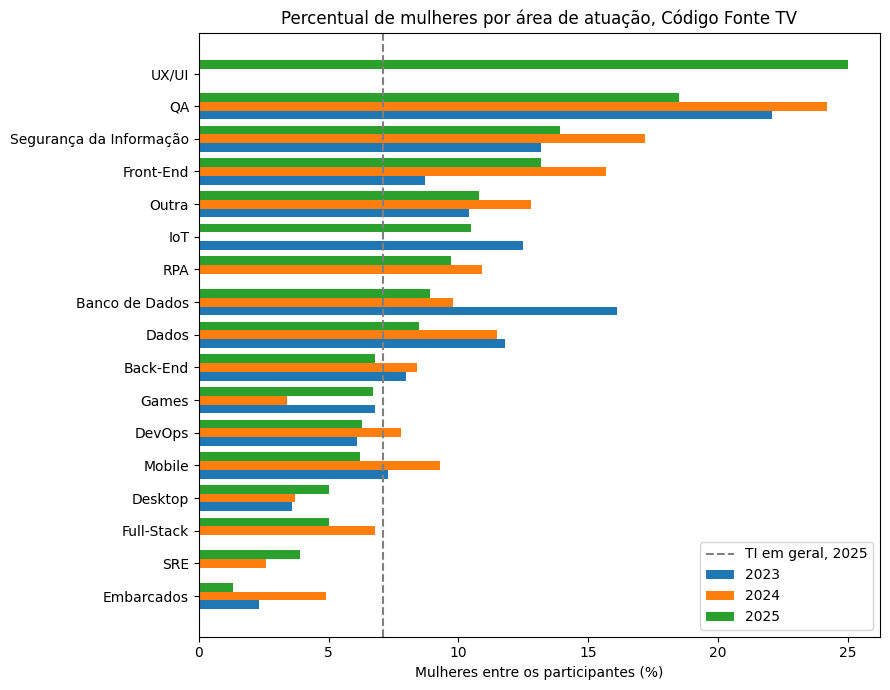

In [ ]:
# Gráfico: percentual de mulheres por área de atuação (Código Fonte TV)
graf = pct_mulheres.drop(index="TI em geral").fillna(0)
ordem = graf.sort_values(2025).index
y = np.arange(len(ordem))
altura = 0.27

fig, ax = plt.subplots(figsize=(9, 7))
for i, ano in enumerate([2023, 2024, 2025]):
    ax.barh(y + (i - 1) * altura, graf.loc[ordem, ano], height=altura, label=str(ano))
ax.axvline(pct_mulheres.loc["TI em geral", 2025], color="gray", linestyle="--", label="TI em geral, 2025")
ax.set_yticks(y)
ax.set_yticklabels(ordem)
ax.set_xlabel("Mulheres entre os participantes (%)")
ax.set_title("Percentual de mulheres por área de atuação, Código Fonte TV")
ax.legend()
plt.tight_layout()
plt.show()

,Ano,Área,Mulheres (n),Lacuna (%),IC 95% inferior,IC 95% superior,Lacuna diferente de zero?
0,2023,Back-End,410,31.9,26.6,36.8,Sim
1,2023,Dados,130,20.6,9.4,31.3,Sim
2,2023,Front-End,686,29.1,24.5,33.6,Sim
3,2023,QA,113,16.9,4.1,28.1,Sim
4,2023,TI em geral,1586,28.9,26.1,31.9,Sim
5,2024,Back-End,391,29.9,24.8,35.0,Sim
6,2024,Front-End,282,20.6,12.2,28.2,Sim
7,2024,Full-Stack,356,28.7,22.6,34.6,Sim
8,2024,TI em geral,1385,28.9,25.8,32.0,Sim
9,2025,Back-End,256,28.4,22.5,34.1,Sim


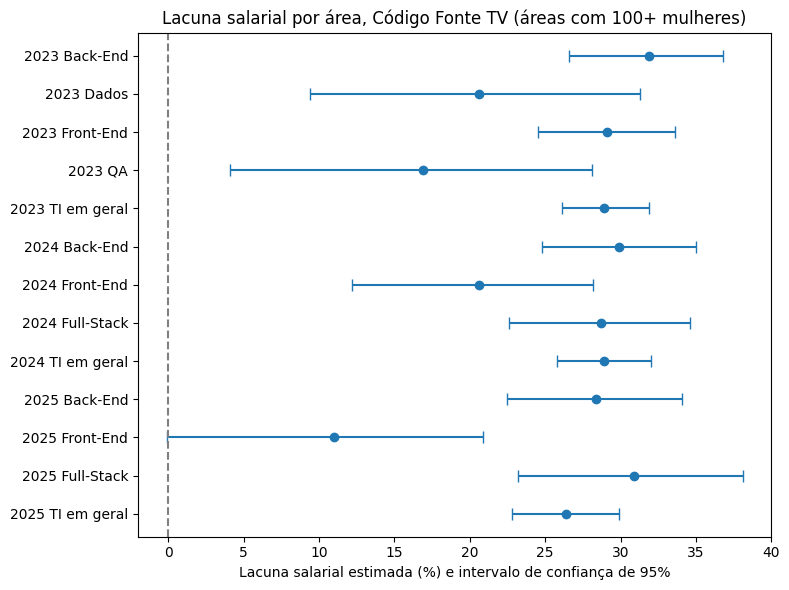

In [ ]:
# Lacuna salarial por área, com intervalo de confiança de 95% (bootstrap, semente 42).
# Só entram áreas com pelo menos 100 mulheres na amostra; abaixo disso a estimativa oscila demais.
rng = np.random.default_rng(42)

def lacuna_ic(chave, repeticoes=3000):
    n, pm, pf, hm, hf = AREAS_CFTV[chave]
    n_m, n_f = round(pm / 100 * n), round(pf / 100 * n)
    prob_m = np.array(hm, dtype=float) / sum(hm)
    prob_f = np.array(hf, dtype=float) / sum(hf)

    def lacuna(cm, cf):
        mm = (cm * PONTOS).sum() / cm.sum()
        mf = (cf * PONTOS).sum() / cf.sum()
        return (mm - mf) / mm * 100

    base = lacuna(prob_m, prob_f)
    sorteios = [lacuna(rng.multinomial(n_m, prob_m), rng.multinomial(n_f, prob_f)) for _ in range(repeticoes)]
    inferior, superior = np.percentile(sorteios, [2.5, 97.5])
    return base, inferior, superior

linhas = []
for chave, valores in AREAS_CFTV.items():
    n_f = round(valores[2] / 100 * valores[0])
    if n_f >= 100:
        base, inferior, superior = lacuna_ic(chave)
        linhas.append({"Ano": chave[0], "Área": NOMES[chave[1]], "Mulheres (n)": n_f, "Lacuna (%)": round(base, 1),
                       "IC 95% inferior": round(inferior, 1), "IC 95% superior": round(superior, 1),
                       "Lacuna diferente de zero?": "Sim" if inferior > 0 else "Não"})
lacuna_areas = pd.DataFrame(linhas).sort_values(["Ano", "Área"]).reset_index(drop=True)
display(lacuna_areas)

# Gráfico: lacuna e intervalo de confiança de cada área/ano
rotulos = lacuna_areas["Ano"].astype(str) + " " + lacuna_areas["Área"]
posicao = np.arange(len(lacuna_areas))[::-1]
erro = [lacuna_areas["Lacuna (%)"] - lacuna_areas["IC 95% inferior"], lacuna_areas["IC 95% superior"] - lacuna_areas["Lacuna (%)"]]
plt.figure(figsize=(8, 6))
plt.errorbar(lacuna_areas["Lacuna (%)"], posicao, xerr=erro, fmt="o", capsize=4)
plt.axvline(0, color="gray", linestyle="--")
plt.yticks(posicao, rotulos)
plt.xlabel("Lacuna salarial estimada (%) e intervalo de confiança de 95%")
plt.title("Lacuna salarial por área, Código Fonte TV (áreas com 100+ mulheres)")
plt.tight_layout()
plt.show()

### Leitura dos resultados por área

- **Onde há mais mulheres:** QA (18,5% a 24,2%) e Segurança da Informação (13,2% a 17,2%) lideram nos três anos. Front-End fica entre 13,2% e 15,7% em 2024 e 2025. UX/UI chega a 25% em 2025, mas com apenas 32 participantes.
- **Onde há menos:** Embarcados (1,3% a 4,9%), SRE (2,6% a 3,9%) e Desktop (3,6% a 5,0%).
- **Dados:** 11,8% (2023), 11,5% (2024) e 8,5% (2025) de mulheres, valores um pouco acima da média de TI em geral (8,9%, 9,2% e 7,1%), mas bem abaixo do State of Data. Isso indica que a diferença entre as duas fontes não vem apenas da área.
- **Lacuna salarial:** nas áreas com amostra grande ela é consistente: Back-End (28% a 32%), Full-Stack (29% a 31% em 2024 e 2025) e TI em geral (26% a 29%). Em Front-End cai de 21% (2024) para 11% (2025), e nesse último ano o intervalo de confiança inclui zero. Em Dados só há mulheres suficientes em 2023 (lacuna de 21%, intervalo de 8% a 31%).
- **Cuidado:** as estimativas usam o ponto médio de cada faixa salarial e contagens aproximadas, e áreas com poucas mulheres não permitem conclusão sobre a lacuna.

# Parte 3 — Comparação entre as duas fontes

Compara o percentual de mulheres no Código Fonte TV (TI em geral) com o State of Data Brazil (área de Dados), ano a ano.

In [ ]:
comp = pd.DataFrame({"Código Fonte TV (%)": cftv["Mulheres (%)"],
                     "State of Data (%)": tabela["Mulheres (%)"]})
comp["Diferença (p.p.)"] = (comp["State of Data (%)"] - comp["Código Fonte TV (%)"]).round(1)
comp["Razão SoD / CFTV"] = (comp["State of Data (%)"] / comp["Código Fonte TV (%)"]).round(1)

# teste qui-quadrado por ano (contagens do Código Fonte TV estimadas a partir dos percentuais)
p_vals = []
for a in comp.index:
    f1 = round(cftv.loc[a, "Participantes"] * cftv.loc[a, "Mulheres (%)"] / 100)
    m1 = round(cftv.loc[a, "Participantes"] * cftv.loc[a, "Homens (%)"] / 100)
    f2 = int((dados[a]["Genero"] == "Feminino").sum())
    m2 = int((dados[a]["Genero"] == "Masculino").sum())
    p_vals.append(stats.chi2_contingency([[f1, m1], [f2, m2]])[1])
comp["p (qui-quadrado)"] = p_vals
comp.style.format({"p (qui-quadrado)": "{:.1e}"})

,Código Fonte TV (%),State of Data (%),Diferença (p.p.),Razão SoD / CFTV,p (qui-quadrado)
Ano,,,,,
2021,5.900000,18.700000,12.800000,3.200000,2.2e-101
2022,7.500000,24.800000,17.300000,3.300000,2.3e-190
2023,8.900000,24.500000,15.600000,2.800000,2.5e-198
2024,9.200000,23.600000,14.400000,2.600000,2.1e-155
2025,7.100000,22.100000,15.000000,3.100000,3.3e-144


### Gráfico — Percentual de mulheres: Código Fonte TV x State of Data Brazil

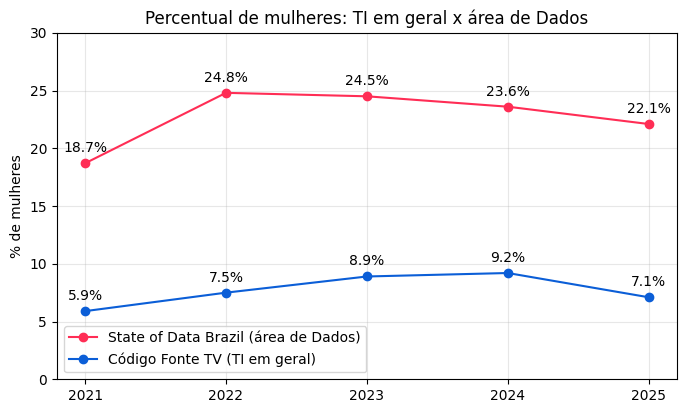

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(comp.index, comp["State of Data (%)"], marker="o", color="#FF2D55", label="State of Data Brazil (área de Dados)")
plt.plot(comp.index, comp["Código Fonte TV (%)"], marker="o", color="#0B5ED7", label="Código Fonte TV (TI em geral)")
for a in comp.index:
    plt.annotate(f"{comp.loc[a, 'State of Data (%)']}%", (a, comp.loc[a, "State of Data (%)"]), textcoords="offset points", xytext=(0, 8), ha="center")
    plt.annotate(f"{comp.loc[a, 'Código Fonte TV (%)']}%", (a, comp.loc[a, "Código Fonte TV (%)"]), textcoords="offset points", xytext=(0, 8), ha="center")
plt.title("Percentual de mulheres: TI em geral x área de Dados")
plt.ylabel("% de mulheres"); plt.xticks(comp.index); plt.ylim(0, 30); plt.legend(); plt.grid(alpha=.3); plt.show()

### Lacuna salarial entre as duas fontes

In [ ]:
comp_sal = pd.DataFrame({
    "Lacuna Código Fonte TV (%)": cftv_sal["Lacuna (%)"],
    "Lacuna State of Data (%)": tabela["Diferença (%)"]})
comp_sal["Diferença (p.p.)"] = (comp_sal["Lacuna Código Fonte TV (%)"] - comp_sal["Lacuna State of Data (%)"]).round(1)
comp_sal

,Lacuna Código Fonte TV (%),Lacuna State of Data (%),Diferença (p.p.)
Ano,,,
2021,25.4,17.1,8.3
2022,27.2,19.0,8.2
2023,28.9,18.0,10.9
2024,28.8,19.3,9.5
2025,26.4,19.4,7.0


### Gráfico — Lacuna salarial: Código Fonte TV x State of Data Brazil

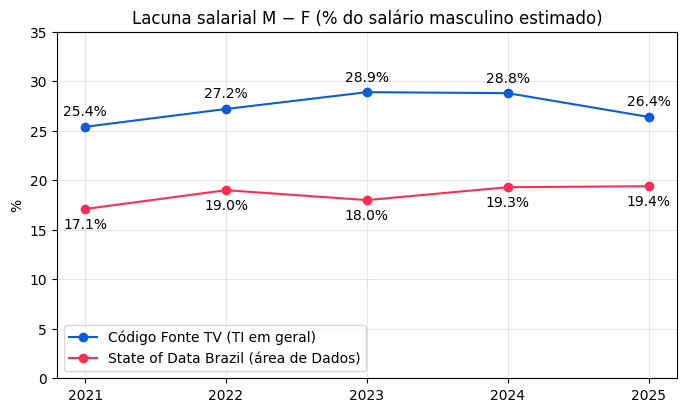

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(comp_sal.index, comp_sal["Lacuna Código Fonte TV (%)"], marker="o", color="#0B5ED7", label="Código Fonte TV (TI em geral)")
plt.plot(comp_sal.index, comp_sal["Lacuna State of Data (%)"], marker="o", color="#FF2D55", label="State of Data Brazil (área de Dados)")
for a in comp_sal.index:
    plt.annotate(f"{comp_sal.loc[a, 'Lacuna Código Fonte TV (%)']}%", (a, comp_sal.loc[a, "Lacuna Código Fonte TV (%)"]), textcoords="offset points", xytext=(0, 8), ha="center")
    plt.annotate(f"{comp_sal.loc[a, 'Lacuna State of Data (%)']}%", (a, comp_sal.loc[a, "Lacuna State of Data (%)"]), textcoords="offset points", xytext=(0, -14), ha="center")
plt.title("Lacuna salarial M − F (% do salário masculino estimado)")
plt.ylabel("%"); plt.xticks(comp_sal.index); plt.ylim(0, 35); plt.legend(); plt.grid(alpha=.3); plt.show()

Fatores de correcao (para R$ de dez/2025)
         SoD    CFTV
2021  1.2185  1.3494
2022  1.1506  1.2032
2023  1.0991  1.1201
2024  1.0481  1.0737
2025  1.0033  1.0148

State of Data - medias em R$ de dez/2025


,Mulheres,Homens,Lacuna (%)
2021,9829.7,11863.4,17.1
2022,9559.3,11801.9,19.0
2023,9876.9,12042.2,18.0
2024,10652.5,13193.0,19.3
2025,11178.8,13868.6,19.4


Codigo Fonte TV - medias em R$ de dez/2025


,Mulheres,Homens,Lacuna (%)
2021,5740.2,7690.0,25.4
2022,6535.7,8980.5,27.2
2023,6571.5,9243.9,28.9
2024,6652.5,9340.0,28.8
2025,7073.0,9609.0,26.4


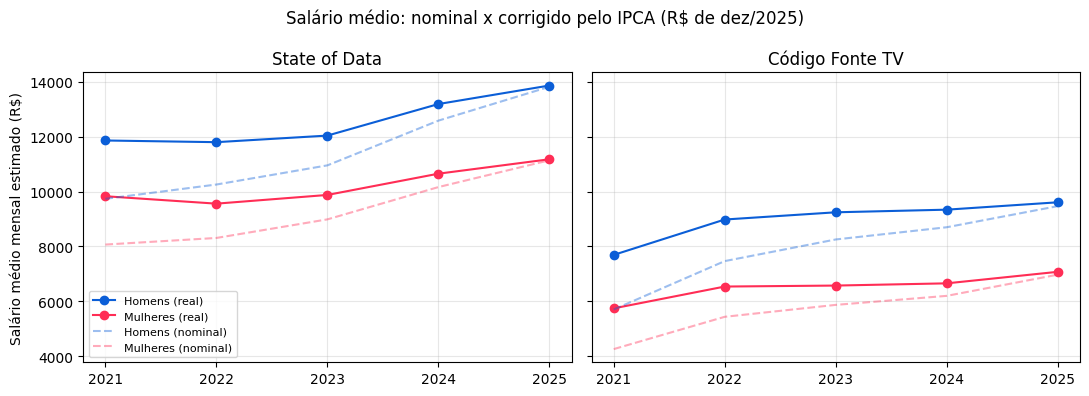

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# IPCA mensal (%) - IBGE, via Banco Central (SGS 433)
IPCA = {
 2020:[0.21,0.25,0.07,-0.31,-0.38,0.26,0.36,0.24,0.64,0.86,0.89,1.35],
 2021:[0.25,0.86,0.93,0.31,0.83,0.53,0.96,0.87,1.16,1.25,0.95,0.73],
 2022:[0.54,1.01,1.62,1.06,0.47,0.67,-0.68,-0.36,-0.29,0.59,0.41,0.62],
 2023:[0.53,0.84,0.71,0.61,0.23,-0.08,0.12,0.23,0.26,0.24,0.28,0.56],
 2024:[0.42,0.83,0.16,0.38,0.46,0.21,0.38,-0.02,0.44,0.56,0.39,0.52],
 2025:[0.16,1.31,0.56,0.43,0.26,0.24,0.26,-0.11,0.48,0.09,0.18,0.33]}
BASE = (2025, 12)  # data-base: dez/2025

def fator(ano, mes):
    """Fator que leva R$ do mes/ano de referencia para R$ de dez/2025 (inflacao dos meses seguintes)."""
    f = 1.0
    for a in range(ano, 2026):
        for m in range(1, 13):
            if (a, m) > (ano, mes) and (a, m) <= BASE:
                f *= 1 + IPCA[a][m-1]/100
    return f

# mes de referencia = meio do periodo de coleta de cada edicao
REF_SOD  = {2021:(2021,11), 2022:(2022,11), 2023:(2023,11), 2024:(2024,11), 2025:(2025,11)}
REF_CFTV = {2021:(2020,11), 2022:(2022,1),  2023:(2023,3),  2024:(2024,4),  2025:(2025,5)}
f_sod  = {a: fator(*m) for a, m in REF_SOD.items()}
f_cftv = {a: fator(*m) for a, m in REF_CFTV.items()}

# medias nominais (R$) - State of Data (mulheres, homens)
sod = pd.DataFrame({"Mulheres": {2021:8067,2022:8308,2023:8986,2024:10164,2025:11142},
                    "Homens":   {2021:9736,2022:10257,2023:10956,2024:12588,2025:13823}})
# medias nominais - Codigo Fonte TV (media estimada pelos pontos medios das faixas, ja calculada na Parte 2)
cf = pd.DataFrame({"Mulheres": {2021:4254,2022:5432,2023:5867,2024:6196,2025:6970},
                   "Homens":   {2021:5699,2022:7464,2023:8253,2024:8699,2025:9469}})

def real(df, fat):
    out = df.astype(float)
    for a in out.index: out.loc[a] = df.loc[a] * fat[a]
    out["Lacuna (%)"] = (out["Homens"] - out["Mulheres"]) / out["Homens"] * 100
    return out.round(1)

sod_r, cf_r = real(sod, f_sod), real(cf, f_cftv)
print("Fatores de correcao (para R$ de dez/2025)")
print(pd.DataFrame({"SoD": f_sod, "CFTV": f_cftv}).round(4))
print("\nState of Data - medias em R$ de dez/2025"); display(sod_r)
print("Codigo Fonte TV - medias em R$ de dez/2025"); display(cf_r)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for x, (nome, nom, rea) in zip(ax, [("State of Data", sod, sod_r), ("Código Fonte TV", cf, cf_r)]):
    x.plot(rea.index, rea["Homens"], marker="o", color="#0B5ED7", label="Homens (real)")
    x.plot(rea.index, rea["Mulheres"], marker="o", color="#FF2D55", label="Mulheres (real)")
    x.plot(nom.index, nom["Homens"], ls="--", color="#0B5ED7", alpha=.4, label="Homens (nominal)")
    x.plot(nom.index, nom["Mulheres"], ls="--", color="#FF2D55", alpha=.4, label="Mulheres (nominal)")
    x.set_title(nome); x.set_xticks(rea.index); x.grid(alpha=.3)
ax[0].set_ylabel("Salário médio mensal estimado (R$)"); ax[0].legend(fontsize=8)
plt.suptitle("Salário médio: nominal x corrigido pelo IPCA (R$ de dez/2025)"); plt.tight_layout(); plt.show()
